# Лабораторная работа 2
## Проваторов Роман M3407

### Классификация эмоций по ЭЭГ

- один вектор признаков на весь trial;
- мощность в 5 ритмах через Welch;
- логистическая регрессия;

Данные: `prep/prep` (распакованный `Preprocessed_EEG`).

In [27]:
from __future__ import annotations
%matplotlib inline

import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import scipy.io as sio
from scipy.signal import welch, butter, detrend, filtfilt, iirnotch, sosfiltfilt
from scipy.stats import kurtosis, skew
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score, precision_recall_fscore_support
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import RidgeClassifier
from tqdm.auto import tqdm

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 120

ROOT = Path(".").resolve()
if not (ROOT / "prep").exists() and (Path("/mnt/c/Research/SEED") / "prep").exists():
    ROOT = Path("/mnt/c/Research/SEED")


def find_data_dir(root: Path) -> Path:
    for cand in (root / "prep" / "prep", root / "prep", root / "Preprocessed_EEG"):
        if (cand / "label.mat").exists():
            return cand
    raise FileNotFoundError("Не найден label.mat")


DATA_DIR = find_data_dir(ROOT)
CACHE = ROOT / "cache"
CACHE.mkdir(exist_ok=True)
FEATURE_CACHE = CACHE / "seed_simple_trial_logbp.npz"

FS = 200
BANDS = {"delta": (1, 4), "theta": (4, 8), "alpha": (8, 14), "beta": (14, 31), "gamma": (31, 50)}
EMOTION = {-1: "negative", 0: "neutral", 1: "positive"}
EMOTION_COLOR = {"negative": "#c0392b", "neutral": "#7f8c8d", "positive": "#27ae60"}

print("DATA_DIR:", DATA_DIR)

MINIMAL_CACHE = CACHE / "seed_full_trial_features_v1.npz"

CHANNELS = (
    "FP1", "FPZ", "FP2", "AF3", "AF4", "F7", "F5", "F3", "F1", "FZ",
    "F2", "F4", "F6", "F8", "FT7", "FC5", "FC3", "FC1", "FCZ", "FC2",
    "FC4", "FC6", "FT8", "T7", "C5", "C3", "C1", "CZ", "C2", "C4",
    "C6", "T8", "TP7", "CP5", "CP3", "CP1", "CPZ", "CP2", "CP4", "CP6",
    "TP8", "P7", "P5", "P3", "P1", "PZ", "P2", "P4", "P6", "P8",
    "PO7", "PO5", "PO3", "POZ", "PO4", "PO6", "PO8", "CB1", "O1", "OZ",
    "O2", "CB2",
)

DATA_DIR: C:\Users\Roman\MainFolder\University\ISIT\lab-2\prep


## Данные

SEED: 15 человек, до 3 сессий, 15 фильм-клипов в сессии. Метки одни на всех:
`+1` positive, `0` neutral, `−1` negative.

В `.mat` лежат массивы `{инициалы}_eeg1 … eeg15` формы `(62 канала, T отсчётов)`, 200 Hz.

In [28]:
def session_files(data_dir: Path) -> list[Path]:
    return sorted(p for p in data_dir.glob("*.mat") if p.name != "label.mat")


def load_labels(data_dir: Path) -> np.ndarray:
    return sio.loadmat(data_dir / "label.mat", verify_compressed_data_integrity=False)["label"].astype(int).ravel()


def trial_keys(mat: dict) -> list[str]:
    keys = [k for k in mat if not k.startswith("__") and re.search(r"eeg\d+$", k)]
    return sorted(keys, key=lambda k: int(re.search(r"(\d+)$", k).group(1)))


def load_session(path: Path) -> tuple[list[np.ndarray], int]:
    mat = sio.loadmat(path, verify_compressed_data_integrity=False)
    trials = [np.asarray(mat[k], dtype=np.float64) for k in trial_keys(mat)]
    subject = int(path.stem.split("_")[0])
    return trials, subject


TRIAL_LABELS = load_labels(DATA_DIR)
FILES = session_files(DATA_DIR)
print(f"сессий: {len(FILES)}, метки trial: {TRIAL_LABELS}")

demo_trials, demo_subj = load_session(DATA_DIR / "1_20131027.mat")
print(f"пример: испытуемый {demo_subj}, trial 1 shape={demo_trials[0].shape}, {demo_trials[0].shape[1] / FS:.0f} с")


сессий: 44, метки trial: [ 1  0 -1 -1  0  1 -1  0  1  1  0 -1  0  1 -1]
пример: испытуемый 1, trial 1 shape=(62, 47001), 235 с


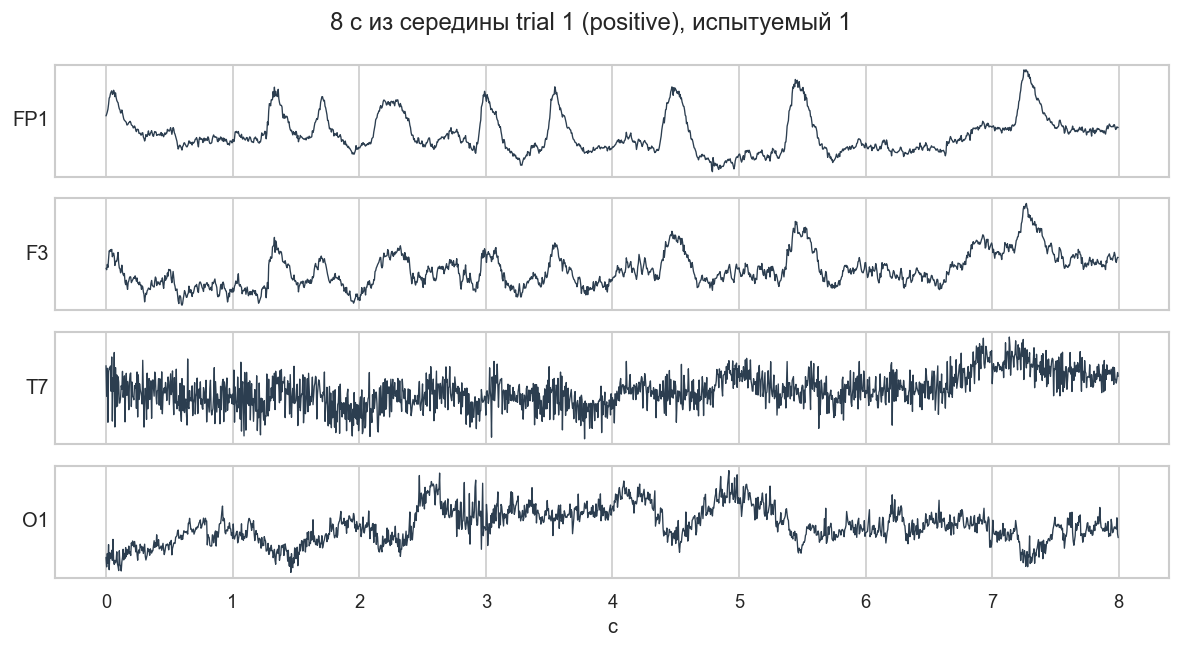

In [29]:
ch_show = [0, 7, 23, 58]  # FP1, F3, T7, O1 в порядке SEED
ch_names = ["FP1", "F3", "T7", "O1"]
n = int(8 * FS)
mid = demo_trials[0].shape[1] // 2
t = np.arange(n) / FS

fig, axes = plt.subplots(len(ch_show), 1, figsize=(10, 5.5), sharex=True)
for ax, idx, name in zip(axes, ch_show, ch_names):
    ax.plot(t, demo_trials[0][idx, mid : mid + n], color="#2c3e50", lw=0.8)
    ax.set_ylabel(name, rotation=0, ha="right", va="center")
    ax.set_yticks([])
axes[-1].set_xlabel("с")
fig.suptitle("8 с из середины trial 1 (positive), испытуемый 1")
fig.tight_layout()
plt.show()

## Предварительная обработка сигнала

Версия `Preprocessed_EEG` уже частично обработана: частота дискретизации снижена с 1000 Гц до 200 Гц, выполнена полосовая фильтрация 0-75 Гц и удалены грубые артефакты. 

Дополнительная фильтрация состоит из:

1. удаление линейного тренда
2. подавления сетевой наводки 50 Гц notch-фильтром
3. добавление полосового фильтра 1-45 Гц

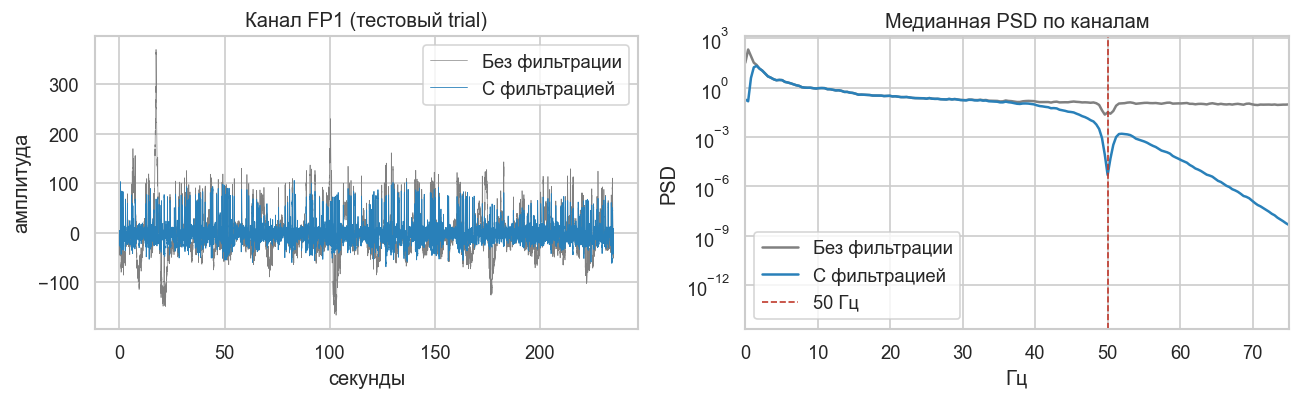

In [30]:
NOTCH_B, NOTCH_A = iirnotch(50.0, Q=30.0, fs=FS)
BANDPASS_SOS = butter(4, (1.0, 45.0), btype="bandpass", fs=FS, output="sos")

def preprocess_trial(eeg: np.ndarray) -> np.ndarray:
    signal = detrend(eeg, axis=1, type="linear")
    signal = filtfilt(NOTCH_B, NOTCH_A, signal, axis=1)
    signal = sosfiltfilt(BANDPASS_SOS, signal, axis=1)
    return signal

example_raw = demo_trials[0]
example_filtered = preprocess_trial(example_raw)
freq_raw, psd_raw = welch(example_raw, fs=FS, nperseg=512, axis=1)
freq_filtered, psd_filtered = welch(example_filtered, fs=FS, nperseg=512, axis=1)
plot_t = np.arange(example_raw.shape[1]) / FS

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot(plot_t, example_raw[0], color="gray", lw=0.4, label="Без фильтрации")
axes[0].plot(plot_t, example_filtered[0], color="#2980b9", lw=0.5, label="С фильтрацией")
axes[0].set(title="Канал FP1 (тестовый trial)", xlabel="секунды", ylabel="амплитуда")
axes[0].legend()
axes[1].semilogy(freq_raw, np.median(psd_raw, axis=0), color="gray", label="Без фильтрации")
axes[1].semilogy(freq_filtered, np.median(psd_filtered, axis=0), color="#2980b9", label="С фильтрацией")
axes[1].axvline(50, color="#c0392b", ls="--", lw=1, label="50 Гц")
axes[1].set(xlim=(0, 75), title="Медианная PSD по каналам", xlabel="Гц", ylabel="PSD")
axes[1].legend()
fig.tight_layout()
plt.show()

## Признаки: log-мощность пяти ритмов

На каждый trial считаем Welch-PSD по 62 каналам и берём $\log$ мощности в полосах
delta / theta / alpha / beta / gamma. Получается вектор длины **310** на клип.

In [31]:
def trial_log_bandpower(eeg: np.ndarray) -> np.ndarray:
    freqs, psd = welch(eeg, fs=FS, nperseg=1024, axis=1)
    parts = []
    for lo, hi in BANDS.values():
        mask = (freqs >= lo) & (freqs < hi)
        power = np.trapezoid(psd[:, mask], freqs[mask], axis=1).clip(min=1e-8)
        parts.append(np.log(power))
    return np.concatenate(parts)


def extract_dataset(files, labels):
    Xs, ys, subjects, trial_ids = [], [], [], []
    for path in tqdm(files, desc="sessions"):
        trials, subject = load_session(path)
        for trial_i, eeg in enumerate(trials):
            Xs.append(trial_log_bandpower(eeg))
            ys.append(labels[trial_i])
            subjects.append(subject)
            trial_ids.append(trial_i)
    return {
        "X": np.stack(Xs).astype(np.float32),
        "y": np.asarray(ys, dtype=np.int8),
        "subject": np.asarray(subjects, dtype=np.int16),
        "trial": np.asarray(trial_ids, dtype=np.int8),
    }


if FEATURE_CACHE.exists():
    packed = np.load(FEATURE_CACHE)
    data = {k: packed[k] for k in packed.files}
    print("кэш", FEATURE_CACHE)
else:
    data = extract_dataset(FILES, TRIAL_LABELS)
    np.savez_compressed(FEATURE_CACHE, **data)
    print("записан", FEATURE_CACHE)

X, y, subject = data["X"], data["y"].astype(int), data["subject"].astype(int)
trial = data["trial"].astype(int) if "trial" in data else np.arange(len(y)) % 15
print("X", X.shape, "— trial × (62 канала × 5 ритмов)")
print(pd.Series([EMOTION[v] for v in y]).value_counts())

кэш C:\Users\Roman\MainFolder\University\ISIT\lab-2\cache\seed_simple_trial_logbp.npz
X (660, 310) — trial × (62 канала × 5 ритмов)
positive    220
neutral     220
negative    220
Name: count, dtype: int64


Для сравнения формируются два набора признаков:

- **bandpower**: исходные 310 признаков мощности ритмов;
- **bandpower и статистики**: к исходным признакам мощности ритмов добавляются среднее, стандартное отклонение, асимметрия и эксцесс каждого канала, всего 558 признаков.

In [32]:
def trial_filtered_features(eeg: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    signal = preprocess_trial(eeg)
    bandpower = trial_log_bandpower(signal)
    statistics = np.concatenate([
        np.mean(signal, axis=1),
        np.std(signal, axis=1),
        skew(signal, axis=1, bias=False),
        kurtosis(signal, axis=1, fisher=True, bias=False),
    ])
    return bandpower, np.concatenate([bandpower, statistics])


def extract_filtered_dataset(files, labels):
    filtered_bands, filtered_full = [], []
    targets, subjects, trial_ids = [], [], []
    for path in tqdm(files, desc="filtered features"):
        trials, subject_id = load_session(path)
        for trial_i, eeg in enumerate(trials):
            filtered, full = trial_filtered_features(eeg)
            filtered_bands.append(filtered)
            filtered_full.append(full)
            targets.append(labels[trial_i])
            subjects.append(subject_id)
            trial_ids.append(trial_i)
    return {
        "X_filtered_bands": np.asarray(filtered_bands, dtype=np.float32),
        "X_filtered_full": np.asarray(filtered_full, dtype=np.float32),
        "y": np.asarray(targets, dtype=np.int8),
        "subject": np.asarray(subjects, dtype=np.int16),
        "trial": np.asarray(trial_ids, dtype=np.int8),
    }


if MINIMAL_CACHE.exists():
    packed = np.load(MINIMAL_CACHE)
    comparison_data = {key: packed[key] for key in packed.files}
    print("кэш", MINIMAL_CACHE)
else:
    comparison_data = extract_filtered_dataset(FILES, TRIAL_LABELS)
    np.savez_compressed(MINIMAL_CACHE, **comparison_data)
    print("записан", MINIMAL_CACHE)

X_raw_bands = X
X_filtered_bands = comparison_data["X_filtered_bands"]
X_filtered_full = comparison_data["X_filtered_full"]
y_comparison = comparison_data["y"].astype(int)
trial_comparison = comparison_data["trial"].astype(int)

assert np.array_equal(y, y_comparison)
assert np.array_equal(trial, trial_comparison)
print("без дополнительной фильтрации:", X_raw_bands.shape)
print("после фильтрации, мощности ритмов:", X_filtered_bands.shape)
print("после фильтрации, мощности и статистики:", X_filtered_full.shape)

кэш C:\Users\Roman\MainFolder\University\ISIT\lab-2\cache\seed_full_trial_features_v1.npz
без дополнительной фильтрации: (660, 310)
после фильтрации, мощности ритмов: (660, 310)
после фильтрации, мощности и статистики: (660, 558)


## Обучение и проверка

In [33]:
train = trial < 9
test = trial >= 9
print(f"train trials={train.sum()} (клипы 1–9)")
print(f"test  trials={test.sum()} (клипы 10–15)")
print("испытуемые в train и test одни и те же:", sorted(np.unique(subject)))

clf = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=2000),
)
clf.fit(X[train], y[train])
pred = clf.predict(X[test])

acc = accuracy_score(y[test], pred)
f1 = f1_score(y[test], pred, average="macro")
print(f"accuracy = {acc:.3f}")
print(f"macro-F1 = {f1:.3f}")
print(f"случайный уровень для 3 классов = {1/3:.3f}")

train trials=396 (клипы 1–9)
test  trials=264 (клипы 10–15)
испытуемые в train и test одни и те же: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15)]
accuracy = 0.689
macro-F1 = 0.667
случайный уровень для 3 классов = 0.333


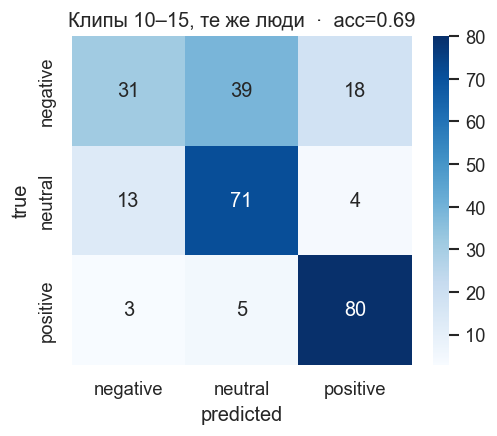

              precision    recall  f1-score   support

    negative      0.660     0.352     0.459        88
     neutral      0.617     0.807     0.700        88
    positive      0.784     0.909     0.842        88

    accuracy                          0.689       264
   macro avg      0.687     0.689     0.667       264
weighted avg      0.687     0.689     0.667       264



In [34]:
labels = [-1, 0, 1]
names = [EMOTION[i] for i in labels]
cm = confusion_matrix(y[test], pred, labels=labels)

fig, ax = plt.subplots(figsize=(4.4, 3.8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax, xticklabels=names, yticklabels=names)
ax.set_xlabel("predicted")
ax.set_ylabel("true")
ax.set_title(f"Клипы 10–15, те же люди  ·  acc={acc:.2f}")
fig.tight_layout()
plt.show()

print(classification_report(y[test], pred, labels=labels, target_names=names, digits=3))

## Сравнение предобработки, признаков и моделей

Сравниваются 6 вариантов:

1. bandpower без дополнительной фильтрации, Logistic Regression
2. bandpower после фильтрации, Logistic Regression
3. bandpower и статистики после фильтрации, Logistic Regression
4. bandpower без дополнительной фильтрации, Ridge Classifier
5. bandpower после фильтрации, Ridge Classifier
6. bandpower и статистики после фильтрации, Ridge Classifier

,Вариант,Accuracy,Precision,Recall,Macro-F1
0,"С фильтром, bandpower, Ridge",0.716,0.719,0.716,0.712
1,"С фильтром, bandpower и статистики, Ridge",0.716,0.712,0.716,0.708
2,"Без доп. фильтра, bandpower, Ridge",0.712,0.715,0.712,0.706
3,"С фильтром, bandpower, LogReg",0.693,0.695,0.693,0.669
4,"Без доп. фильтра, bandpower, LogReg",0.689,0.687,0.689,0.667
5,"С фильтром, bandpower и статистики, LogReg",0.652,0.640,0.652,0.632


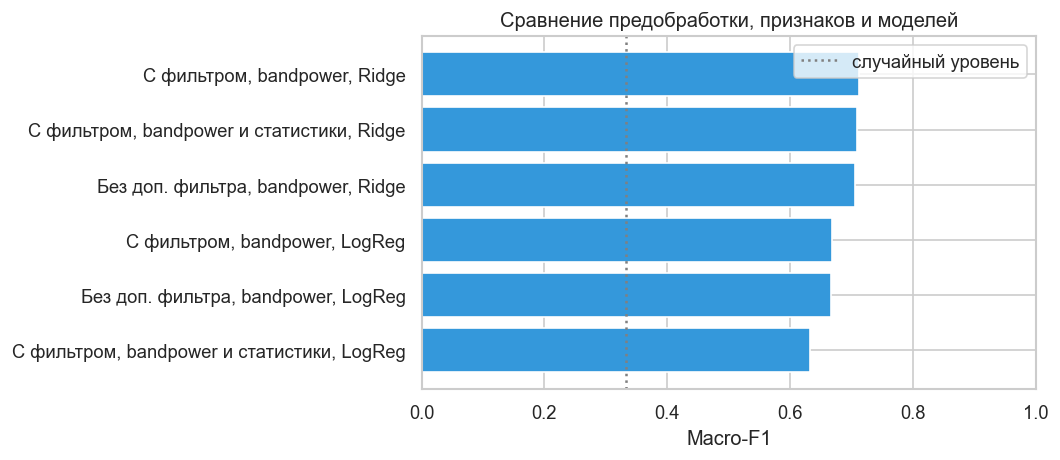

Лучший вариант: С фильтром, bandpower, Ridge
              precision    recall  f1-score   support

    negative      0.691     0.534     0.603        88
     neutral      0.648     0.795     0.714        88
    positive      0.818     0.818     0.818        88

    accuracy                          0.716       264
   macro avg      0.719     0.716     0.712       264
weighted avg      0.719     0.716     0.712       264



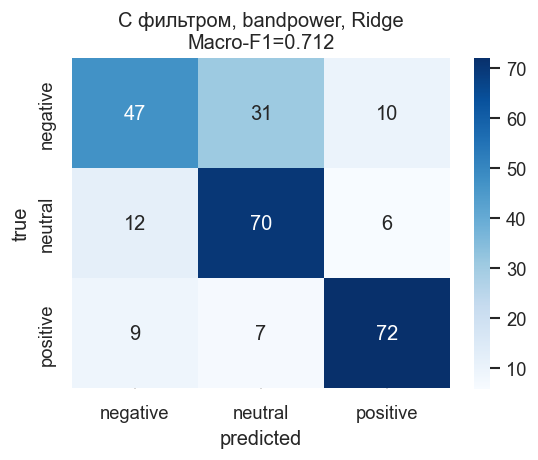

In [35]:
train_comparison = trial_comparison < 9
test_comparison = trial_comparison >= 9

def model_metrics(name: str, model, matrix: np.ndarray):
    model.fit(matrix[train_comparison], y_comparison[train_comparison])
    prediction = model.predict(matrix[test_comparison])
    precision, recall, f1_macro, _ = precision_recall_fscore_support(
        y_comparison[test_comparison], prediction, average="macro", zero_division=0
    )
    row = {
        "Вариант": name,
        "Accuracy": accuracy_score(y_comparison[test_comparison], prediction),
        "Precision": precision,
        "Recall": recall,
        "Macro-F1": f1_macro,
    }
    return row, prediction, model

variants = {
    "Без доп. фильтра, bandpower, LogReg": (
        make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)), X_raw_bands
    ),
    "С фильтром, bandpower, LogReg": (
        make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)), X_filtered_bands
    ),
    "С фильтром, bandpower и статистики, LogReg": (
        make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)), X_filtered_full
    ),
    "Без доп. фильтра, bandpower, Ridge": (
        make_pipeline(StandardScaler(), RidgeClassifier()), X_raw_bands
    ),
    "С фильтром, bandpower, Ridge": (
        make_pipeline(StandardScaler(), RidgeClassifier()), X_filtered_bands
    ),
    "С фильтром, bandpower и статистики, Ridge": (
        make_pipeline(StandardScaler(), RidgeClassifier()), X_filtered_full
    ),
}

rows, predictions, fitted_models = [], {}, {}
for variant_name, (estimator, matrix) in variants.items():
    row, prediction, fitted = model_metrics(variant_name, estimator, matrix)
    rows.append(row)
    predictions[variant_name] = prediction
    fitted_models[variant_name] = fitted

results = pd.DataFrame(rows).sort_values("Macro-F1", ascending=False).reset_index(drop=True)
display(results.style.format({column: "{:.3f}" for column in ["Accuracy", "Precision", "Recall", "Macro-F1"]}))

fig, ax = plt.subplots(figsize=(9, 4))
plot_data = results.iloc[::-1]
ax.barh(plot_data["Вариант"], plot_data["Macro-F1"], color="#3498db")
ax.axvline(1 / 3, color="gray", ls=":", label="случайный уровень")
ax.set(xlim=(0, 1), xlabel="Macro-F1", title="Сравнение предобработки, признаков и моделей")
ax.legend()
fig.tight_layout()
plt.show()

best_name = results.loc[0, "Вариант"]
best_prediction = predictions[best_name]
best_model = fitted_models[best_name]

labels = [-1, 0, 1]
names = [EMOTION[value] for value in labels]
print("Лучший вариант:", best_name)
print(classification_report(
    y_comparison[test_comparison], best_prediction,
    labels=labels, target_names=names, digits=3, zero_division=0,
))

cm_final = confusion_matrix(y_comparison[test_comparison], best_prediction, labels=labels)
fig, ax = plt.subplots(figsize=(4.8, 4))
sns.heatmap(cm_final, annot=True, fmt="d", cmap="Blues", ax=ax,
            xticklabels=names, yticklabels=names)
ax.set_xlabel("predicted")
ax.set_ylabel("true")
ax.set_title(f"{best_name}\nMacro-F1={results.loc[0, 'Macro-F1']:.3f}")
fig.tight_layout()
plt.show()

## Информативные зоны и ритмы

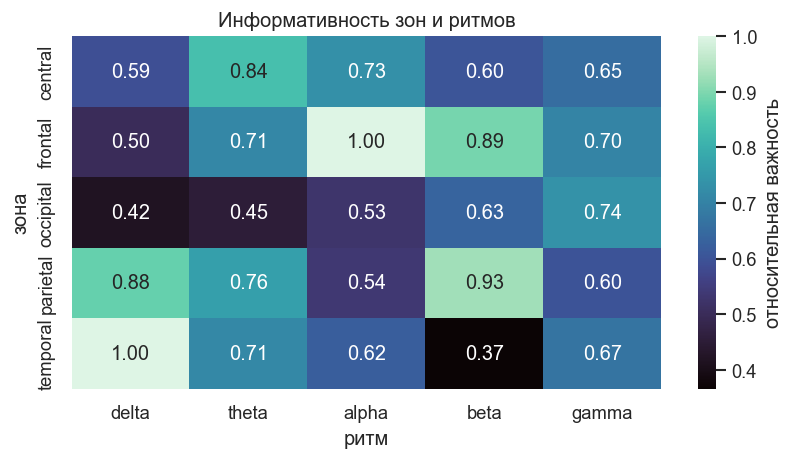

Зоны:
region
frontal      0.1936
parietal     0.1883
central      0.1735
temporal     0.1713
occipital    0.1405
dtype: float32

Ритмы:
band
theta    0.1766
beta     0.1740
alpha    0.1735
delta    0.1721
gamma    0.1709
dtype: float32


In [36]:
def channel_region(name: str) -> str:
    if name.startswith(("PO", "O", "CB")):
        return "occipital"
    if name.startswith(("FT", "TP", "T")):
        return "temporal"
    if name.startswith(("FC", "CP", "C")):
        return "central"
    if name.startswith("P"):
        return "parietal"
    return "frontal"


band_model = make_pipeline(StandardScaler(), RidgeClassifier())
band_model.fit(X_filtered_bands[train_comparison], y_comparison[train_comparison])
importance = np.abs(band_model.named_steps["ridgeclassifier"].coef_).mean(axis=0)

importance_rows = []
for band_i, band in enumerate(BANDS):
    for channel_i, channel in enumerate(CHANNELS):
        importance_rows.append({
            "region": channel_region(channel),
            "band": band,
            "importance": importance[band_i * len(CHANNELS) + channel_i],
        })

importance_table = pd.DataFrame(importance_rows)
pivot = importance_table.groupby(["region", "band"])["importance"].mean().unstack()[list(BANDS)]
relative_pivot = pivot / pivot.to_numpy().max()

fig, ax = plt.subplots(figsize=(7, 4))
sns.heatmap(relative_pivot, annot=True, fmt=".2f", cmap="mako", ax=ax,
            cbar_kws={"label": "относительная важность"})
ax.set_xlabel("ритм")
ax.set_ylabel("зона")
ax.set_title("Информативность зон и ритмов")
fig.tight_layout()
plt.show()

region_importance = pivot.mean(axis=1).sort_values(ascending=False)
band_importance = pivot.mean(axis=0).sort_values(ascending=False)
print("Зоны:")
print(region_importance.round(4))
print()
print("Ритмы:")
print(band_importance.round(4))